# ♻️SMART WASTE CLASSIFICATION♻️

**Course:** Deep Learning

**Course Code:** CSL312

**Project:** Smart Waste Classification  

**Proposed Deep Learning Model:** EfficientNet  

**Baseline ML Model:** Random Forest and Support Vector Machine (SVM)

### Name- AAYUSH KATARIA
### ROLL NO.- 23csu006

## PROBLEM STATEMENT AND OBJECTIVE
Traditional waste segregation is often performed manually, which is time-consuming and prone to human error. The objective is to develop an image-based system that can automatically classify different types of waste such as plastic, paper, glass, metal, cardboard, clothes, biological waste, batteries, shoes, and trash using Machine Learning and Deep Learning techniques.

The system will automatically identify different types of waste from images using Machine Learning and Deep Learning to make waste separation easier and faster.

## DATASET DESCRIPTION

**Dataset Name:** Garbage-dataset-10-classes.

THE Dataset has been selected from Kaggle.

The dataset contains images of different types of waste.
- Battery
- Biological
- Cardboard
- Clothes
- Glass
- Metal
- Paper
- Plastic
- Shoes
- Trash

## 1️⃣ GPU CHECK

In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

print("\nAvailable GPUs:")
print(tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0

Available GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2️⃣ LOADING API TOKEN

In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import userdata
import os

kaggle_token = userdata.get("KAGGLE_API_TOKEN")

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

print("Kaggle token loaded successfully ✅")

Kaggle token loaded successfully ✅


## 3️⃣ KAGGLE CONNECTION TEST

In [ ]:
!kaggle datasets list -s "garbage dataset 9 classes"

ref                                                 title                                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------  ----------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
mostafaabla/garbage-classification                  Garbage Classification (12 classes)               250641573  2021-01-24 13:53:11.647000          46750        288  0.8125           
idrisskh/obstacles-dataset                          obstacles dataset                                 246312660  2024-11-27 17:04:00.130000           1347          7  0.5              
tasneemselim/img-classification-competition         Img_classification_competition                   5659646434  2026-04-29 16:27:43.643000            201          2  0.4375           
mintumovi/residential-activity-capture-datasetracd  Residential Activity Ca

## 4️⃣ Exact Dataset Files Check

In [ ]:
!kaggle datasets files sudipp/garbage-dataset-9-classes

Next Page Token = CfDJ8DXPm6Y-hepMoQLWDOQfJcn7qwuZczUOn36__Qszug3iGBVylF7zMVMc6TGK6GQrdtTB-I03BQ5xef3xs6C018PRgJ1Z3x_ag924aYYdXzOeZDjXBr-cnWRD2islZmU55OQO70WspSyXJUSqISLpCm1xtnkqcTTNtVqO7DNrhNGVO_sieA0
name                                            size  creationDate                
---------------------------------------------  -----  --------------------------  
garbage_classification/battery/battery1.jpg     7405  2025-06-07 04:10:46.542000  
garbage_classification/battery/battery10.jpg    4900  2025-06-07 04:10:46.195000  
garbage_classification/battery/battery100.jpg  12976  2025-06-07 04:10:46.322000  
garbage_classification/battery/battery101.jpg   9825  2025-06-07 04:10:46.401000  
garbage_classification/battery/battery102.jpg   3111  2025-06-07 04:10:46.243000  
garbage_classification/battery/battery103.jpg   8327  2025-06-07 04:10:46.180000  
garbage_classification/battery/battery104.jpg  11425  2025-06-07 04:10:45.932000  
garbage_classification/battery/battery105.jpg   489

## 5️⃣ DATASET DOWNLOAD

In [ ]:
!kaggle datasets download -d sudipp/garbage-dataset-9-classes

Dataset URL: https://www.kaggle.com/datasets/sudipp/garbage-dataset-9-classes
License(s): unknown
100% 489M/489M [00:26<00:00, 19.6MB/s]



In [ ]:
!ls -lh

total 489M
-rw-r--r-- 1 root root 489M Jun  7  2025 garbage-dataset-9-classes.zip
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


## 6️⃣ DATASET EXTRACT

In [ ]:
import os

os.makedirs("/content/garbage_dataset", exist_ok=True)

!unzip -q garbage-dataset-9-classes.zip -d /content/garbage_dataset

## 7️⃣ EXTRACT FOLDER STRUCTURE CHECK

In [ ]:
import os

dataset_root = "/content/garbage_dataset"

for root, dirs, files in os.walk(dataset_root):
    level = root.replace(dataset_root, '').count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

garbage_dataset/
    garbage_classification/
        glass/
        trash/
        biological/
        metal/
        shoes/
        plastic/
        paper/
        clothes/
        battery/
        cardboard/


## 8️⃣ SET ACTUAL DATASET PATH

In [ ]:
DATASET_PATH = "/content/garbage_dataset/garbage_classification"

## 9️⃣ COUNT TOTAL IMAGES

In [ ]:
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in Path(DATASET_PATH).rglob("*")
    if p.suffix.lower() in image_extensions
]

print("Total Images:", len(image_files))

Total Images: 20029


## 🔟 CLASS WISE IMAGES

In [ ]:
from collections import Counter

class_counts = Counter(
    image.parent.name for image in image_files
)

print("Number of Classes:", len(class_counts))
print("\nClass-wise Image Count:\n")

for cls, count in sorted(class_counts.items()):
    print(f"{cls:15s} : {count}")

Number of Classes: 10

Class-wise Image Count:

battery         : 1889
biological      : 1982
cardboard       : 2328
clothes         : 2106
glass           : 2011
metal           : 1789
paper           : 2310
plastic         : 1993
shoes           : 1977
trash           : 1644


## 1️⃣1️⃣ IMPORTING LIBRARIES

In [ ]:
import os
import random
import json
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.utils import load_img, img_to_array

from tensorflow.keras.applications import EfficientNetB0

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

from google.colab import files

from tqdm.auto import tqdm

print("✅ All required libraries imported successfully!")


✅ All required libraries imported successfully!


## 1️⃣2️⃣ CLASS DISTRIBUTION VISUALIZATION

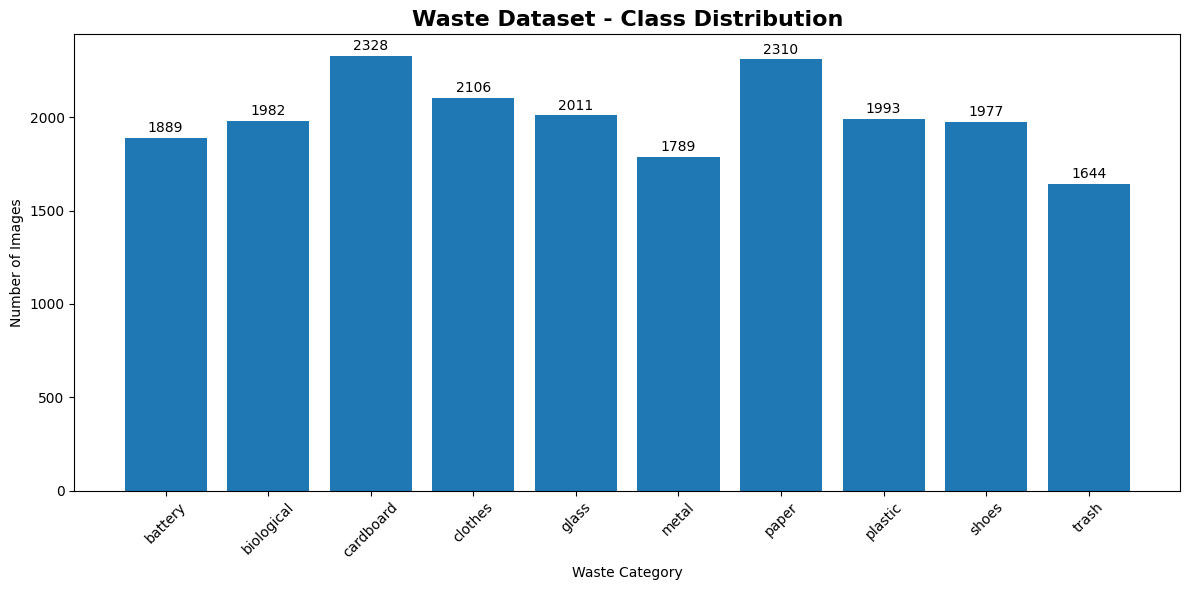

In [ ]:
class_names = sorted(class_counts.keys())

counts = [class_counts[class_name] for class_name in class_names]

plt.figure(figsize=(12, 6))

bars = plt.bar(class_names, counts)

plt.title("Waste Dataset - Class Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 30,
        str(count),
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

## 1️⃣3️⃣ DISPLAY SAMPLE IMAGES

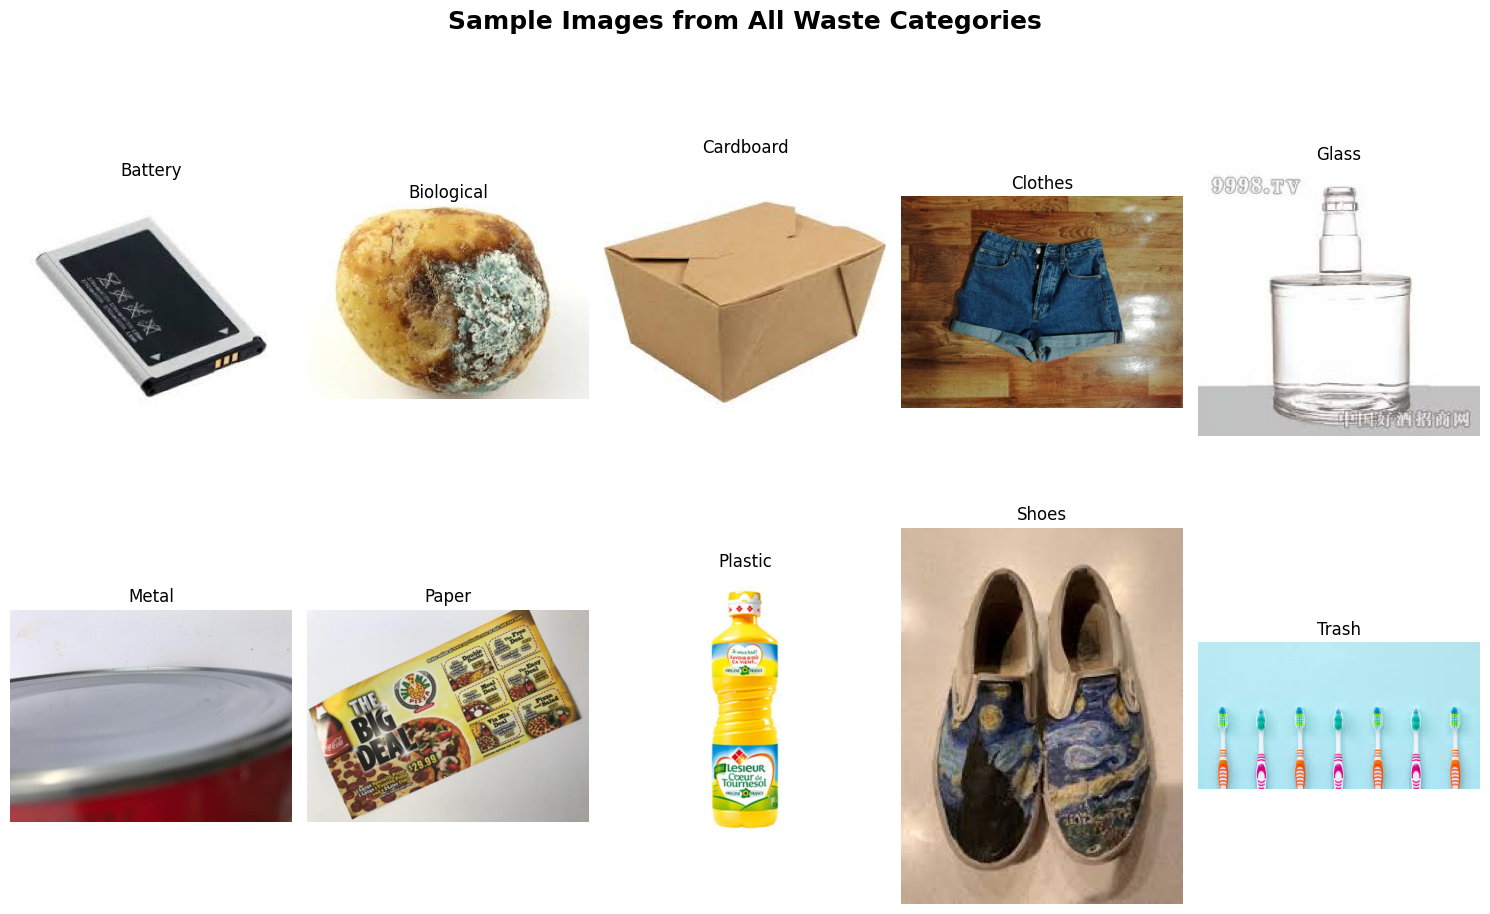

In [ ]:
import random

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(class_names):

    class_images = list(
        Path(DATASET_PATH, class_name).glob("*")
    )

    image_path = random.choice(class_images)

    image = Image.open(image_path)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.suptitle(
    "Sample Images from All Waste Categories",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 1️⃣4️⃣  IMAGE SIZE ANALYSIS

In [ ]:
widths = []
heights = []

sample_images = random.sample(
    image_files,
    min(2000, len(image_files))
)

for image_path in sample_images:
    try:
        with Image.open(image_path) as img:
            widths.append(img.width)
            heights.append(img.height)
    except:
        pass

print("Average Width :", np.mean(widths))
print("Average Height:", np.mean(heights))
print("Minimum Width :", np.min(widths))
print("Maximum Width :", np.max(widths))
print("Minimum Height:", np.min(heights))
print("Maximum Height:", np.max(heights))

Average Width : 372.208
Average Height: 340.049
Minimum Width : 114
Maximum Width : 4032
Minimum Height: 138
Maximum Height: 3750


## 1️⃣5️⃣  IMAGE DIMENSION VISUALIZATION

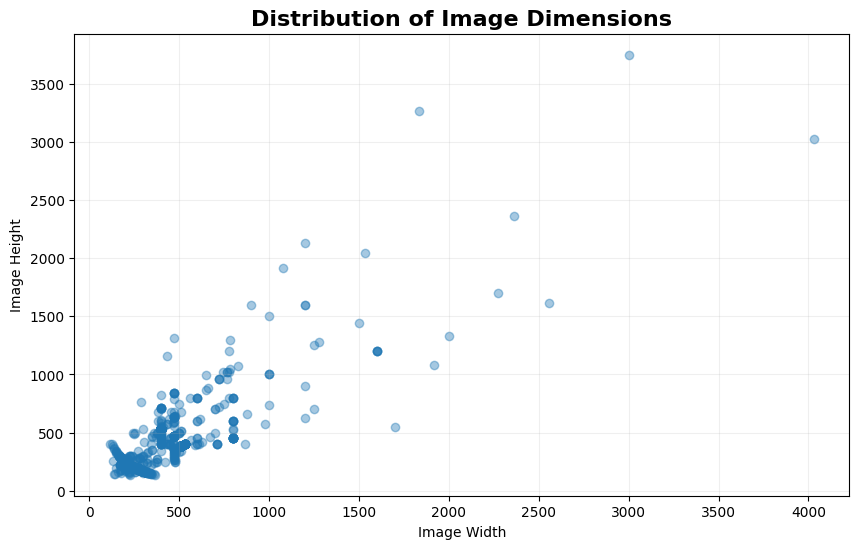

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(widths, heights, alpha=0.4)

plt.title("Distribution of Image Dimensions", fontsize=16, fontweight="bold")
plt.xlabel("Image Width")
plt.ylabel("Image Height")

plt.grid(alpha=0.2)

plt.show()

## 1️⃣6️⃣  CHECK CORRUPTED IMAGE

In [ ]:
corrupted_images = []

for image_path in image_files:
    try:
        with Image.open(image_path) as img:
            img.verify()
    except:
        corrupted_images.append(str(image_path))

print("Total Images:", len(image_files))
print("Corrupted Images:", len(corrupted_images))

Total Images: 20029
Corrupted Images: 0


## 1️⃣7️⃣ DATASET DATA FRAME

In [ ]:
data = []

for image_path in image_files:

    data.append({
        "filepath": str(image_path),
        "class": image_path.parent.name
    })

df = pd.DataFrame(data)

print(df.head())
print("\nShape:", df.shape)

                                            filepath  class
0  /content/garbage_dataset/garbage_classificatio...  glass
1  /content/garbage_dataset/garbage_classificatio...  glass
2  /content/garbage_dataset/garbage_classificatio...  glass
3  /content/garbage_dataset/garbage_classificatio...  glass
4  /content/garbage_dataset/garbage_classificatio...  glass

Shape: (20029, 2)


## 1️⃣8️⃣  DATASET SUMMARY

In [ ]:
print("Total Images :", len(df))
print("Total Classes:", df["class"].nunique())

print("\nClasses:")
print(df["class"].value_counts())

Total Images : 20029
Total Classes: 10

Classes:
class
cardboard     2328
paper         2310
clothes       2106
glass         2011
plastic       1993
biological    1982
shoes         1977
battery       1889
metal         1789
trash         1644
Name: count, dtype: int64


## 1️⃣9️⃣  TRAIN / VALIDATION / TEST SPLIT

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=42
)

print("Training Images  :", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images   :", len(test_df))

Training Images  : 14020
Validation Images: 3004
Testing Images   : 3005


## 2️⃣0️⃣  VERIFY SPLIT

In [ ]:
print("TRAIN:")
print(train_df["class"].value_counts().sort_index())

print("\nVALIDATION:")
print(val_df["class"].value_counts().sort_index())

print("\nTEST:")
print(test_df["class"].value_counts().sort_index())

TRAIN:
class
battery       1322
biological    1387
cardboard     1630
clothes       1474
glass         1408
metal         1252
paper         1617
plastic       1395
shoes         1384
trash         1151
Name: count, dtype: int64

VALIDATION:
class
battery       284
biological    297
cardboard     349
clothes       316
glass         301
metal         269
paper         346
plastic       299
shoes         296
trash         247
Name: count, dtype: int64

TEST:
class
battery       283
biological    298
cardboard     349
clothes       316
glass         302
metal         268
paper         347
plastic       299
shoes         297
trash         246
Name: count, dtype: int64


## 2️⃣1️⃣  Load EfficientNetB0 Feature Extractor

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0

feature_extractor = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

feature_extractor.trainable = False

feature_extractor.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

## 2️⃣2️⃣ Create Image Preprocessing Function

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

IMG_SIZE = (224, 224)

def preprocess_image(image_path):
    image = load_img(
        image_path,
        target_size=IMG_SIZE
    )

    image = img_to_array(image)

    image = np.expand_dims(image, axis=0)

    return image

## 2️⃣3️⃣  Create Class Mapping

In [ ]:
class_names = sorted(df["class"].unique())

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("Class Mapping:")

for class_name, index in class_to_index.items():
    print(index, "→", class_name)

Class Mapping:
0 → battery
1 → biological
2 → cardboard
3 → clothes
4 → glass
5 → metal
6 → paper
7 → plastic
8 → shoes
9 → trash


## 2️⃣4️⃣  Function to Extract Features

In [ ]:
def extract_features(dataframe):

    features = []
    labels = []

    for i, (_, row) in enumerate(dataframe.iterrows()):

        image = preprocess_image(row["filepath"])

        feature = feature_extractor.predict(
            image,
            verbose=0
        )

        features.append(feature[0])
        labels.append(class_to_index[row["class"]])

        if (i + 1) % 500 == 0:
            print(f"Processed {i + 1}/{len(dataframe)} images")

    return np.array(features), np.array(labels)

## 2️⃣5️⃣  EXTRACT TRAINING FEATURES

In [ ]:
X_train, y_train = extract_features(train_df)

Processed 500/14020 images
Processed 1000/14020 images
Processed 1500/14020 images
Processed 2000/14020 images
Processed 2500/14020 images
Processed 3000/14020 images
Processed 3500/14020 images
Processed 4000/14020 images
Processed 4500/14020 images
Processed 5000/14020 images
Processed 5500/14020 images
Processed 6000/14020 images
Processed 6500/14020 images
Processed 7000/14020 images
Processed 7500/14020 images
Processed 8000/14020 images
Processed 8500/14020 images
Processed 9000/14020 images
Processed 9500/14020 images
Processed 10000/14020 images
Processed 10500/14020 images
Processed 11000/14020 images
Processed 11500/14020 images
Processed 12000/14020 images
Processed 12500/14020 images
Processed 13000/14020 images
Processed 13500/14020 images
Processed 14000/14020 images


In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (14020, 1280)
y_train shape: (14020,)


## 2️⃣6️⃣  VALIDATION FEATURES

In [ ]:
X_val, y_val = extract_features(val_df)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

Processed 500/3004 images
Processed 1000/3004 images
Processed 1500/3004 images
Processed 2000/3004 images
Processed 2500/3004 images
Processed 3000/3004 images
X_val shape: (3004, 1280)
y_val shape: (3004,)


## 2️⃣7️⃣  TEST FEATURES

In [ ]:
X_test, y_test = extract_features(test_df)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Processed 500/3005 images
Processed 1000/3005 images
Processed 1500/3005 images
Processed 2000/3005 images
Processed 2500/3005 images
Processed 3000/3005 images
X_test shape: (3005, 1280)
y_test shape: (3005,)


## 💾 SAVE FEATURES

In [ ]:
np.save("/content/X_train.npy", X_train)
np.save("/content/y_train.npy", y_train)

np.save("/content/X_val.npy", X_val)
np.save("/content/y_val.npy", y_val)

np.save("/content/X_test.npy", X_test)
np.save("/content/y_test.npy", y_test)

print("Features saved successfully ✅")

Features saved successfully ✅


## 2️⃣8️⃣  RANDOM FOREST BASELINE

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed ✅")

Random Forest training completed ✅


## 2️⃣9️⃣  RANDOM FOREST EVALUATION

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(
    y_test,
    rf_pred,
    average="weighted"
)
rf_recall = recall_score(
    y_test,
    rf_pred,
    average="weighted"
)
rf_f1 = f1_score(
    y_test,
    rf_pred,
    average="weighted"
)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

Random Forest Results
---------------------
Accuracy : 0.9498
Precision: 0.9503
Recall   : 0.9498
F1 Score : 0.9495


In [ ]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     battery       0.97      0.98      0.97       283
  biological       0.97      1.00      0.99       298
   cardboard       0.97      0.98      0.97       349
     clothes       0.98      0.97      0.98       316
       glass       0.94      0.89      0.91       302
       metal       0.88      0.94      0.91       268
       paper       0.92      0.95      0.94       347
     plastic       0.93      0.89      0.91       299
       shoes       0.95      0.99      0.97       297
       trash       0.98      0.88      0.93       246

    accuracy                           0.95      3005
   macro avg       0.95      0.95      0.95      3005
weighted avg       0.95      0.95      0.95      3005



## 3️⃣0️⃣ RANDOM FOREST CONFUSION MATRIX

<Figure size 1000x800 with 0 Axes>

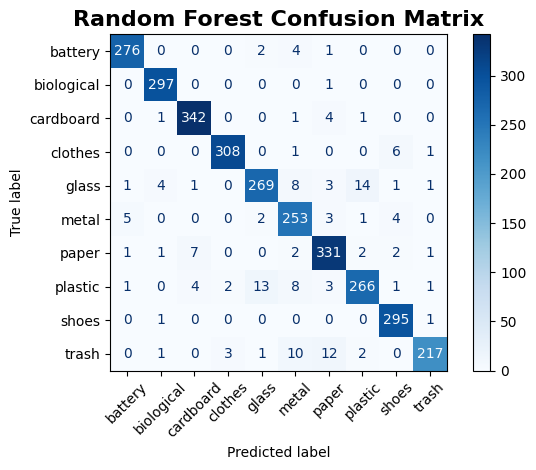

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title(
    "Random Forest Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 3️⃣1️⃣  SVM MODEL

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(X_train, y_train)

print("SVM training completed ✅")

SVM training completed ✅


## 3️⃣2️⃣  SVM EVALUATION

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

svm_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)

svm_precision = precision_score(
    y_test,
    svm_pred,
    average="weighted"
)

svm_recall = recall_score(
    y_test,
    svm_pred,
    average="weighted"
)

svm_f1 = f1_score(
    y_test,
    svm_pred,
    average="weighted"
)

print("SVM Results")
print("---------------------")
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"F1 Score : {svm_f1:.4f}")

SVM Results
---------------------
Accuracy : 0.9737
Precision: 0.9739
Recall   : 0.9737
F1 Score : 0.9737


## 3️⃣3️⃣ SVM CLASSIFICATION REPORT

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        svm_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     battery       1.00      0.99      0.99       283
  biological       1.00      1.00      1.00       298
   cardboard       0.99      0.98      0.98       349
     clothes       1.00      0.98      0.99       316
       glass       0.94      0.95      0.95       302
       metal       0.94      0.97      0.96       268
       paper       0.96      0.98      0.97       347
     plastic       0.97      0.93      0.95       299
       shoes       0.99      1.00      0.99       297
       trash       0.96      0.96      0.96       246

    accuracy                           0.97      3005
   macro avg       0.97      0.97      0.97      3005
weighted avg       0.97      0.97      0.97      3005



## 3️⃣4️⃣  SVM CONFUSION MATRIX

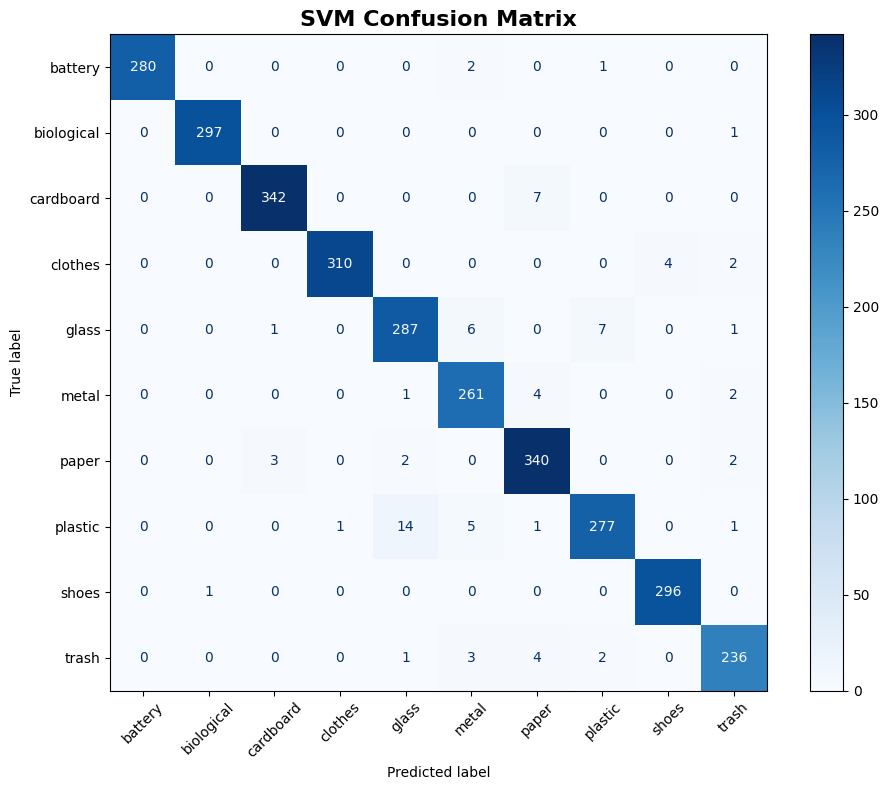

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_svm = confusion_matrix(y_test, svm_pred)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

ax.set_title(
    "SVM Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 3️⃣5️⃣ RANDOM FOREST VS SVM COMPARISION TABLE

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        rf_accuracy,
        svm_accuracy
    ],
    "Precision": [
        rf_precision,
        svm_precision
    ],
    "Recall": [
        rf_recall,
        svm_recall
    ],
    "F1 Score": [
        rf_f1,
        svm_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.94975,0.950272,0.94975,0.949526
1,SVM,0.97371,0.973922,0.97371,0.973719


## 3️⃣6️⃣  RANDOM FOREST VS SVM COMPARISION GRAPH

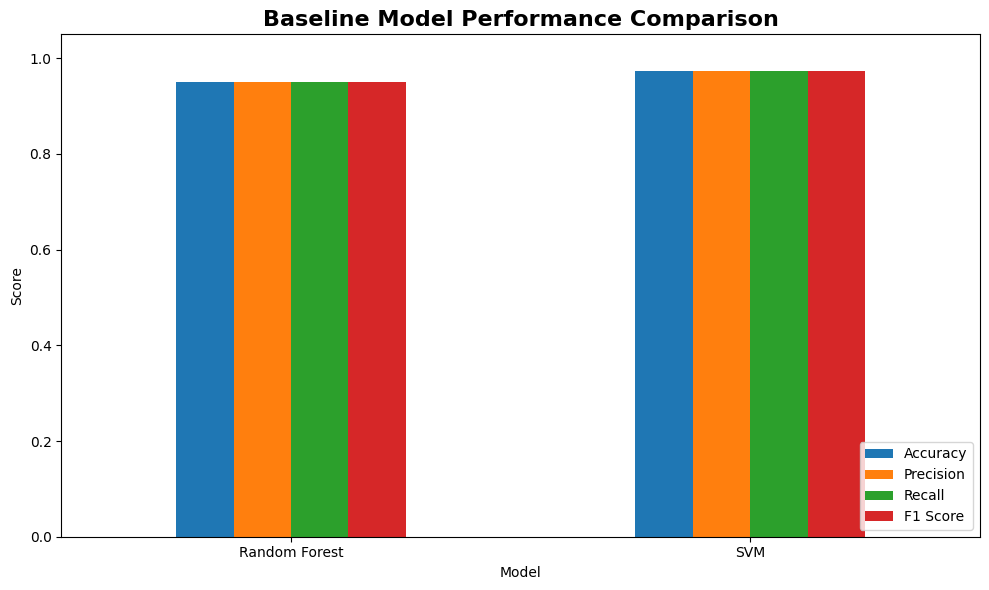

In [ ]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Baseline Model Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import joblib
import shutil

CHECKPOINT_DIR = "/content/smart_waste_checkpoint"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Feature arrays
np.save(f"{CHECKPOINT_DIR}/X_train.npy", X_train)
np.save(f"{CHECKPOINT_DIR}/y_train.npy", y_train)

np.save(f"{CHECKPOINT_DIR}/X_val.npy", X_val)
np.save(f"{CHECKPOINT_DIR}/y_val.npy", y_val)

np.save(f"{CHECKPOINT_DIR}/X_test.npy", X_test)
np.save(f"{CHECKPOINT_DIR}/y_test.npy", y_test)

# Dataset splits
df.to_csv(f"{CHECKPOINT_DIR}/dataset_metadata.csv", index=False)
train_df.to_csv(f"{CHECKPOINT_DIR}/train.csv", index=False)
val_df.to_csv(f"{CHECKPOINT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{CHECKPOINT_DIR}/test.csv", index=False)

# Random Forest
joblib.dump(
    rf_model,
    f"{CHECKPOINT_DIR}/random_forest.pkl"
)

# Save SVM only if it has been trained
if 'svm_model' in globals():
    joblib.dump(
        svm_model,
        f"{CHECKPOINT_DIR}/svm.pkl"
    )
    print("SVM saved ✅")

print("All checkpoint files created ✅")

SVM saved ✅
All checkpoint files created ✅


In [ ]:
shutil.make_archive(
    "/content/smart_waste_checkpoint",
    "zip",
    CHECKPOINT_DIR
)

print("Checkpoint ZIP created successfully ✅")

Checkpoint ZIP created successfully ✅


In [ ]:
import os

size_gb = os.path.getsize(
    "/content/smart_waste_checkpoint.zip"
) / (1024**3)

print(f"Checkpoint size: {size_gb:.2f} GB")

Checkpoint size: 0.16 GB


In [ ]:
from google.colab import files

files.download(
    "/content/smart_waste_checkpoint.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3️⃣7️⃣ ANN IMPLEMENTATION


### 1️⃣ LIBRARIES

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("ANN libraries imported successfully!")

ANN libraries imported successfully!


### 2️⃣ ANN MODEL

In [ ]:
ann_model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),

    Dense(256, activation='relu'),
    Dropout(0.3),

    Dense(128, activation='relu'),
    Dropout(0.2),

    Dense(10, activation='softmax')
])

print("ANN model created successfully!")

ANN model created successfully!


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 3️⃣ COMPILATION

In [ ]:
ann_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


### 4️⃣ MODEL SUMMARY

In [ ]:
ann_model.summary()

print("ANN architecture displayed successfully!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 821,386 (3.13 MB)

 Trainable params: 821,386 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

ANN architecture displayed successfully!


### 5️⃣ EARLY STOPPING

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Early stopping configured successfully!")

Early stopping configured successfully!


### 6️⃣ TRAINING ANN

In [ ]:
history = ann_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("ANN training completed successfully!")

Epoch 1/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8752 - loss: 0.3954 - val_accuracy: 0.9464 - val_loss: 0.1729
Epoch 2/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9486 - loss: 0.1678 - val_accuracy: 0.9554 - val_loss: 0.1386
Epoch 3/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9675 - loss: 0.1083 - val_accuracy: 0.9607 - val_loss: 0.1288
Epoch 4/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9745 - loss: 0.0821 - val_accuracy: 0.9594 - val_loss: 0.1531
Epoch 5/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9811 - loss: 0.0644 - val_accuracy: 0.9621 - val_loss: 0.1529
Epoch 6/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9832 - loss: 0.0538 - val_accuracy: 0.9674 - val_loss: 0.1239
Epoch 7/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9864 - loss: 0.0446 - val_accuracy: 0.9720 - val_loss: 0.1339
Epoch 8/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9879 - loss: 0.0425 - val_accuracy: 

### 7️⃣ EVALUATE ANN

In [ ]:
test_loss, test_accuracy = ann_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("ANN evaluation completed successfully!")
print(f"ANN Test Accuracy: {test_accuracy * 100:.2f}%")

ANN evaluation completed successfully!
ANN Test Accuracy: 96.11%


### 8️⃣ PREDICTIONS

In [ ]:
y_pred_prob = ann_model.predict(X_test, verbose=0)
y_pred_ann = y_pred_prob.argmax(axis=1)

print("ANN predictions generated successfully!")

ANN predictions generated successfully!


### 9️⃣ CLASSIFICATION REPORTS

In [ ]:
from sklearn.metrics import classification_report

print("ANN Classification Report:")
print(classification_report(
    y_test,
    y_pred_ann,
    target_names=class_names
))

print("ANN classification report generated successfully!")

ANN Classification Report:
              precision    recall  f1-score   support

     battery       0.98      0.98      0.98       283
  biological       1.00      0.98      0.99       298
   cardboard       0.99      0.97      0.98       349
     clothes       1.00      0.97      0.99       316
       glass       0.94      0.95      0.94       302
       metal       0.91      0.96      0.94       268
       paper       0.96      0.94      0.95       347
     plastic       0.93      0.93      0.93       299
       shoes       0.99      0.98      0.98       297
       trash       0.90      0.95      0.92       246

    accuracy                           0.96      3005
   macro avg       0.96      0.96      0.96      3005
weighted avg       0.96      0.96      0.96      3005

ANN classification report generated successfully!


### 🔟 CONFUSION MATRIX

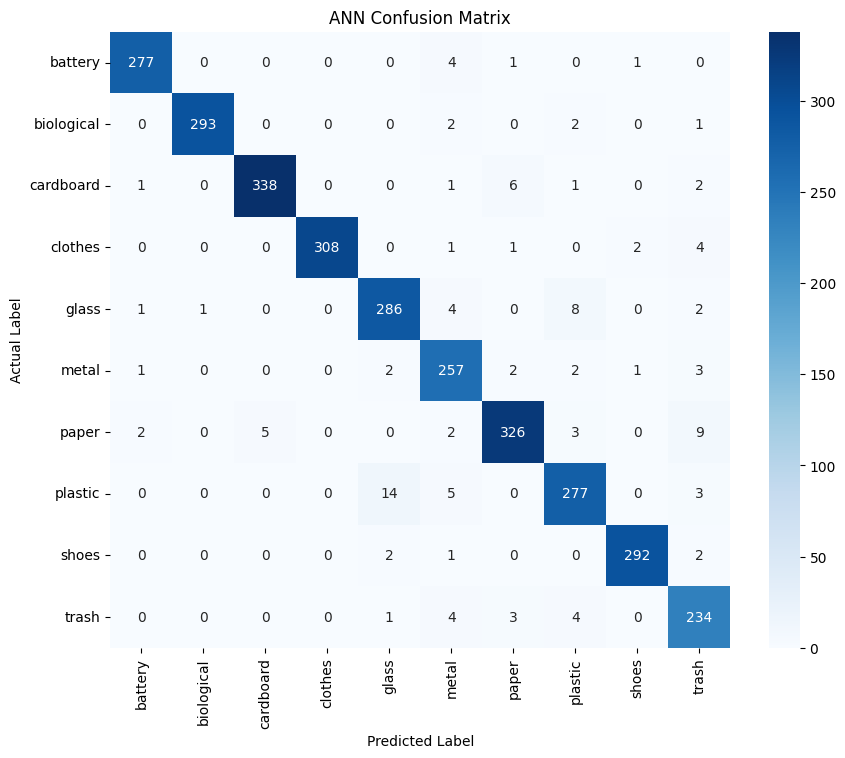

ANN confusion matrix generated successfully!


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_ann = confusion_matrix(y_test, y_pred_ann)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_ann,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ANN Confusion Matrix")
plt.show()

print("ANN confusion matrix generated successfully!")

### 1️⃣1️⃣ ANN ACCURACY GRAPH

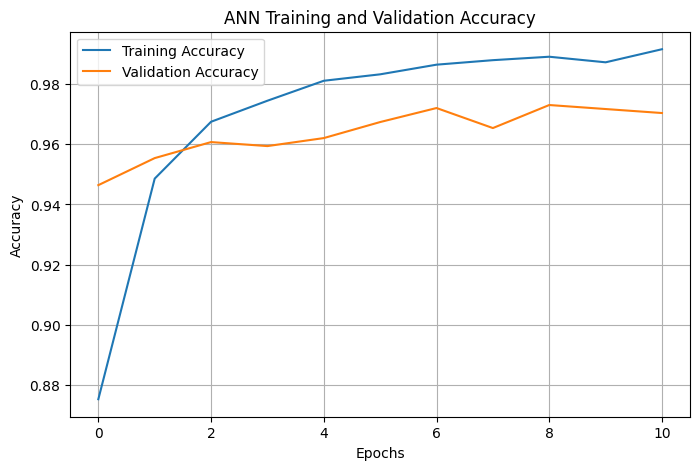

ANN accuracy graph generated successfully!


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

print("ANN accuracy graph generated successfully!")

### 1️⃣2️⃣ ANN LOSS GRAPH

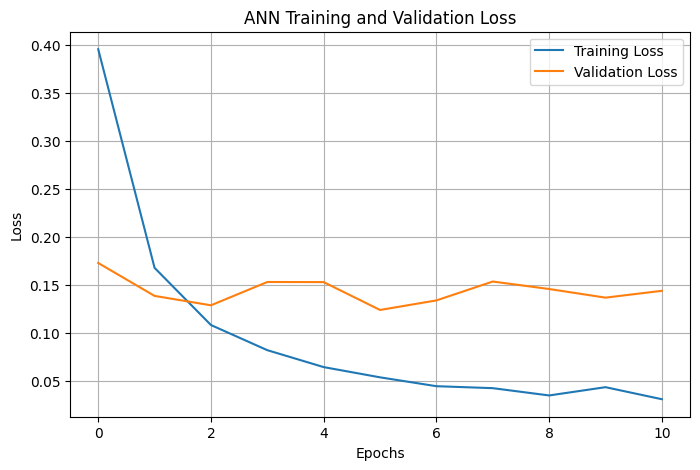

ANN loss graph generated successfully!


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

print("ANN loss graph generated successfully!")

## 3️⃣8️⃣ RANDOM FOREST VS SVM VS ANN COMPARISION

In [ ]:
comparison_all = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "ANN"],
    "Accuracy": [rf_accuracy, svm_accuracy, test_accuracy]
})

comparison_all["Accuracy"] = comparison_all["Accuracy"] * 100

print(comparison_all)
print("RF vs SVM vs ANN comparison completed successfully!")

           Model   Accuracy
0  Random Forest  94.975042
1            SVM  97.371048
2            ANN  96.106488
RF vs SVM vs ANN comparison completed successfully!


## 3️⃣9️⃣ COMPARISON GRAPH

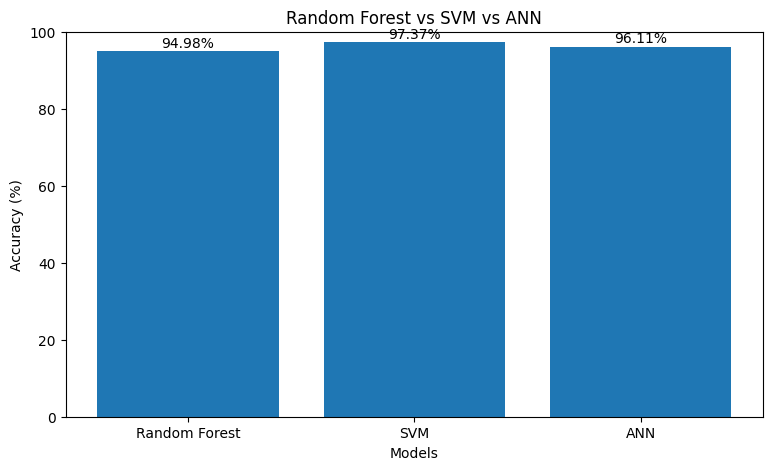

Model comparison graph generated successfully!


In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_all["Model"],
    comparison_all["Accuracy"]
)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Random Forest vs SVM vs ANN")

plt.ylim(0, 100)

for i, value in enumerate(comparison_all["Accuracy"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

print("Model comparison graph generated successfully!")

## 4️⃣0️⃣ CNN IMPLEMENTATION

### 1️⃣CNN LIBRARIES

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dense,
    Dropout,
    Flatten,
    BatchNormalization,
    GlobalAveragePooling2D
)

from tensorflow.keras.callbacks import EarlyStopping

print("CNN libraries imported successfully!")

CNN libraries imported successfully!


### 2️⃣PREPARE IMAGE DATASET

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE

def create_image_dataset(dataframe, shuffle=False):

    image_paths = dataframe["filepath"].values

    labels = dataframe["class"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMG_SIZE)

        image = tf.cast(image, tf.float32) / 255.0

        return image, label

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(2000)

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_image_dataset(train_df, shuffle=True)
val_ds = create_image_dataset(val_df)
test_ds = create_image_dataset(test_df)

print("CNN image datasets prepared successfully!")

CNN image datasets prepared successfully!


### 3️⃣CNN MODEL CREATION

In [ ]:
cnn_model = Sequential([

    tf.keras.Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(NUM_CLASSES, activation='softmax')
])

print("CNN model created successfully!")

CNN model created successfully!


### 4️⃣COMPILE CNN

In [ ]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


### 5️⃣MODEL SUMMARY

In [ ]:
cnn_model.summary()

print("CNN architecture displayed successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,946 (437.29 KB)

 Trainable params: 111,498 (435.54 KB)

 Non-trainable params: 448 (1.75 KB)

CNN architecture displayed successfully!


### 6️⃣TRAIN CNN

In [ ]:
cnn_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[cnn_early_stop],
    verbose=1
)

print("CNN training completed successfully!")

Epoch 1/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 68s 116ms/step - accuracy: 0.4349 - loss: 1.6492 - val_accuracy: 0.2270 - val_loss: 2.3569
Epoch 2/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 55s 84ms/step - accuracy: 0.5225 - loss: 1.4041 - val_accuracy: 0.4075 - val_loss: 1.8450
Epoch 3/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.5672 - loss: 1.2747 - val_accuracy: 0.2224 - val_loss: 3.8237
Epoch 4/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.5922 - loss: 1.2002 - val_accuracy: 0.4970 - val_loss: 1.4348
Epoch 5/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 82ms/step - accuracy: 0.6237 - loss: 1.1049 - val_accuracy: 0.4268 - val_loss: 1.8385
Epoch 6/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.6509 - loss: 1.0308 - val_accuracy: 0.5589 - val_loss: 1.3925
Epoch 7/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.6730 - loss: 0.9774 - val_accuracy: 0.4740 - val_loss: 1.7871
Epoch 8/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 40s 80ms/step - accuracy: 0.6884 - loss: 0.9209 -

### 7️⃣CNN EVALUATION

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    test_ds,
    verbose=1
)

print("CNN evaluation completed successfully!")
print(f"CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step - accuracy: 0.7870 - loss: 0.7009
CNN evaluation completed successfully!
CNN Test Accuracy: 78.70%


### 8️⃣CNN PREDICTIONS AND CLASSIFICATION REPORTS

In [ ]:
from sklearn.metrics import classification_report

cnn_probabilities = cnn_model.predict(test_ds)

cnn_pred = np.argmax(cnn_probabilities, axis=1)

y_test_cnn = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print("CNN Classification Report:")

print(classification_report(
    y_test_cnn,
    cnn_pred,
    target_names=class_names
))

print("CNN classification report generated successfully!")

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step
CNN Classification Report:
              precision    recall  f1-score   support

     battery       0.90      0.86      0.88       283
  biological       0.84      0.94      0.89       298
   cardboard       0.76      0.88      0.82       349
     clothes       0.72      0.93      0.81       316
       glass       0.88      0.67      0.76       302
       metal       0.91      0.71      0.80       268
       paper       0.68      0.88      0.77       347
     plastic       0.79      0.52      0.63       299
       shoes       0.80      0.63      0.70       297
       trash       0.74      0.80      0.77       246

    accuracy                           0.79      3005
   macro avg       0.80      0.78      0.78      3005
weighted avg       0.80      0.79      0.78      3005

CNN classification report generated successfully!


### 9️⃣CNN CONFUSION MATRIX

<Figure size 1000x800 with 0 Axes>

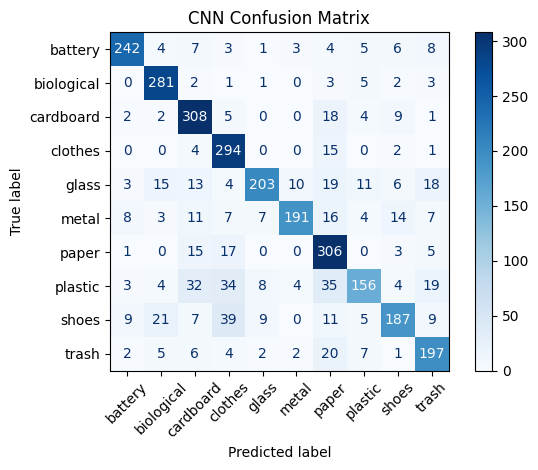

CNN confusion matrix generated successfully!


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_cnn = confusion_matrix(y_test_cnn, cnn_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

print("CNN confusion matrix generated successfully!")

### 1️⃣0️⃣CNN ACCURACY GRAPH

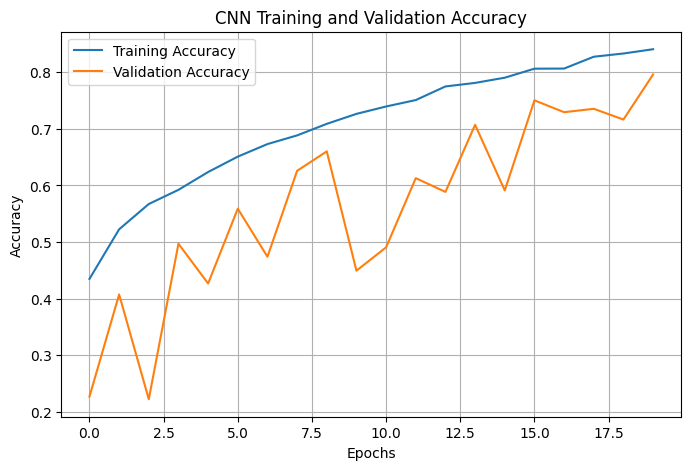

CNN accuracy graph generated successfully!


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    cnn_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

print("CNN accuracy graph generated successfully!")

### 1️⃣1️⃣CNN LOSS GRAPH

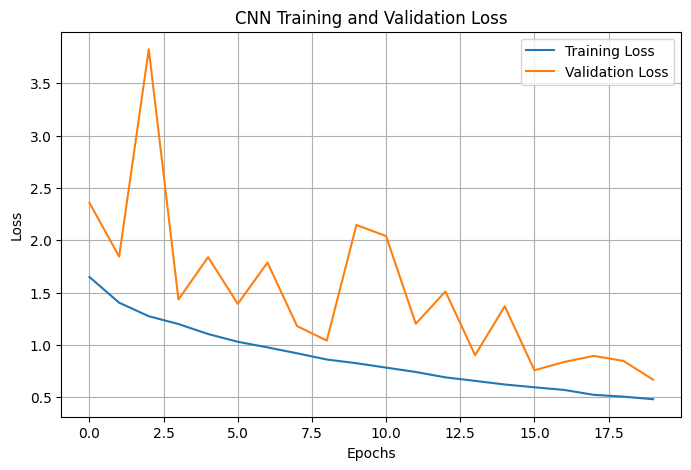

CNN loss graph generated successfully!


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    cnn_history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

print("CNN loss graph generated successfully!")

## 4️⃣1️⃣CNN MODEL FUNCTION

In [ ]:
def build_cnn_model(filters, dropout_rate, learning_rate):

    model = Sequential([

        tf.keras.Input(shape=(224, 224, 3)),

        Conv2D(filters, (3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Conv2D(filters * 2, (3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Conv2D(filters * 4, (3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        GlobalAveragePooling2D(),

        Dense(128, activation='relu'),
        Dropout(dropout_rate),

        Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


print("CNN model function created successfully!")

CNN model function created successfully!


## 4️⃣2️⃣DEFINE GRID SEARCH PARAMETERS

In [ ]:
from itertools import product

filter_values = [32, 64]
learning_rates = [0.001, 0.0001]
dropout_rate = 0.3

parameter_combinations = list(product(
    filter_values,
    learning_rates
))

print("Grid Search combinations:")

for combination in parameter_combinations:
    print(combination)

print("Grid Search parameters defined successfully!")

Grid Search combinations:
(32, 0.001)
(32, 0.0001)
(64, 0.001)
(64, 0.0001)
Grid Search parameters defined successfully!


## 4️⃣3️⃣PERFORM GRID SEARCH

In [ ]:
grid_results = []

best_accuracy = 0
best_cnn_model = None
best_cnn_history = None
best_parameters = None

for filters, learning_rate in parameter_combinations:

    print("\nTesting Configuration:")
    print("Filters:", filters)
    print("Learning Rate:", learning_rate)

    model = build_cnn_model(
        filters,
        dropout_rate,
        learning_rate
    )

    grid_early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=15,
        callbacks=[grid_early_stop],
        verbose=1
    )

    current_accuracy = max(
        history.history['val_accuracy']
    )

    grid_results.append({
        "Filters": filters,
        "Learning Rate": learning_rate,
        "Dropout": dropout_rate,
        "Validation Accuracy": current_accuracy
    })

    if current_accuracy > best_accuracy:

        best_accuracy = current_accuracy

        best_cnn_model = model
        best_cnn_history = history

        best_parameters = {
            "Filters": filters,
            "Learning Rate": learning_rate,
            "Dropout": dropout_rate
        }

    print("Configuration completed successfully!")

print("\nGrid Search completed successfully!")
print("Best Parameters:", best_parameters)
print("Best Validation Accuracy:", best_accuracy)


Testing Configuration:
Filters: 32
Learning Rate: 0.001
Epoch 1/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 50s 96ms/step - accuracy: 0.4350 - loss: 1.6331 - val_accuracy: 0.2600 - val_loss: 2.2609
Epoch 2/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.5214 - loss: 1.4003 - val_accuracy: 0.4923 - val_loss: 1.5202
Epoch 3/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.5634 - loss: 1.2742 - val_accuracy: 0.3642 - val_loss: 2.4904
Epoch 4/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.5945 - loss: 1.2007 - val_accuracy: 0.4427 - val_loss: 1.7455
Epoch 5/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 82ms/step - accuracy: 0.6228 - loss: 1.1151 - val_accuracy: 0.3299 - val_loss: 3.3088
Configuration completed successfully!

Testing Configuration:
Filters: 32
Learning Rate: 0.0001
Epoch 1/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 48s 91ms/step - accuracy: 0.3849 - loss: 1.7870 - val_accuracy: 0.3252 - val_loss: 1.9208
Epoch 2/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 38s 79ms/step - accuracy: 0

## 4️⃣4️⃣GRID SEARCH RESULTS TABLE

In [ ]:
grid_results_df = pd.DataFrame(grid_results)

grid_results_df = grid_results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
)

print(grid_results_df)

print("Grid Search results generated successfully!")

   Filters  Learning Rate  Dropout  Validation Accuracy
3       64         0.0001      0.3             0.659787
1       32         0.0001      0.3             0.655792
2       64         0.0010      0.3             0.623169
0       32         0.0010      0.3             0.492344
Grid Search results generated successfully!


## 4️⃣5️⃣BEST CNN MODEL EVALUATION

In [ ]:
best_cnn_loss, best_cnn_accuracy = best_cnn_model.evaluate(
    test_ds,
    verbose=1
)

print("Best CNN evaluation completed successfully!")
print(f"Best CNN Test Accuracy: {best_cnn_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - accuracy: 0.6436 - loss: 1.0711
Best CNN evaluation completed successfully!
Best CNN Test Accuracy: 64.36%


## 4️⃣6️⃣TRANSFORMER IMPLEMENTATION

### 1️⃣TRANSFORMER LIBRARIES

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    Reshape,
    MultiHeadAttention,
    LayerNormalization,
    Dense,
    Dropout,
    GlobalAveragePooling1D,
    Add
)

from tensorflow.keras.callbacks import EarlyStopping

print("Transformer libraries imported successfully!")

Transformer libraries imported successfully!


### 2️⃣CREATE TRANSFORMER MODEL

In [ ]:
inputs = Input(shape=(224, 224, 3))

# Image Patch Extraction
x = Conv2D(
    128,
    kernel_size=16,
    strides=16,
    padding='valid'
)(inputs)

# Convert patches into sequence
x = Reshape((196, 128))(x)

print("Image patches created successfully!")

attention = MultiHeadAttention(
    num_heads=4,
    key_dim=32,
    output_shape=128
)(x, x)

x = Add()([x, attention])

x = LayerNormalization()(x)

print("First attention block created successfully!")

ffn = Dense(256, activation='relu')(x)

ffn = Dropout(0.1)(ffn)

ffn = Dense(128)(ffn)

x = Add()([x, ffn])

x = LayerNormalization()(x)

print("Feed Forward Network created successfully!")

attention = MultiHeadAttention(
    num_heads=4,
    key_dim=32,
    output_shape=128
)(x, x)

x = Add()([x, attention])

x = LayerNormalization()(x)

print("Second attention block created successfully!")

ffn = Dense(256, activation='relu')(x)

ffn = Dropout(0.1)(ffn)

ffn = Dense(128)(ffn)

x = Add()([x, ffn])

x = LayerNormalization()(x)

print("Second Feed Forward Network created successfully!")

x = GlobalAveragePooling1D()(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.3)(x)

outputs = Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

transformer_model = Model(
    inputs=inputs,
    outputs=outputs
)

print("Transformer model created successfully!")

Image patches created successfully!
First attention block created successfully!
Feed Forward Network created successfully!
Second attention block created successfully!
Second Feed Forward Network created successfully!
Transformer model created successfully!


### 3️⃣COMPILE TRANSFORMER

In [ ]:
transformer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=False
)

print("Transformer model compiled successfully!")

Transformer model compiled successfully!


### 4️⃣TRANSFORMER SUMMARY

In [ ]:
transformer_model.summary()

print("Transformer architecture displayed successfully!")

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 14, 14,    │     98,432 │ input_layer_7[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 128)  │          0 │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ reshape[0][0],    │
│ (MultiHeadAttentio… │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 128)  │          0 │ reshape[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 196, 256)  │          0 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 196, 128)  │     32,896 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 196, 256)  │          0 │ dense_16[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 196, 128)  │     32,896 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dense_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_3[0][0]     

 Total params: 381,194 (1.45 MB)

 Trainable params: 381,194 (1.45 MB)

 Non-trainable params: 0 (0.00 B)

Transformer architecture displayed successfully!


### 5️⃣EARLY STOPPING FOR TRANSFORMER

In [ ]:
transformer_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Transformer Early Stopping configured successfully!")

Transformer Early Stopping configured successfully!


### 6️⃣CHECK OUTPUT SHAPE

In [ ]:
for images, labels in train_ds.take(1):

    predictions = transformer_model(images)

    print("Input Shape:", images.shape)
    print("Output Shape:", predictions.shape)

print("Transformer shape test completed successfully!")

Input Shape: (32, 224, 224, 3)
Output Shape: (32, 10)
Transformer shape test completed successfully!


### 7️⃣TRAIN TRANSFORMER

In [ ]:
transformer_history = transformer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[transformer_early_stop],
    verbose=1
)

print("Transformer training completed successfully!")

Epoch 1/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 42s 71ms/step - accuracy: 0.1708 - loss: 2.2050 - val_accuracy: 0.2570 - val_loss: 2.0673
Epoch 2/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 36s 69ms/step - accuracy: 0.2911 - loss: 1.9835 - val_accuracy: 0.3489 - val_loss: 1.8177
Epoch 3/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 42s 69ms/step - accuracy: 0.3567 - loss: 1.8309 - val_accuracy: 0.4088 - val_loss: 1.7222
Epoch 4/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 32s 67ms/step - accuracy: 0.3984 - loss: 1.7327 - val_accuracy: 0.4604 - val_loss: 1.6224
Epoch 5/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 33s 70ms/step - accuracy: 0.4245 - loss: 1.6659 - val_accuracy: 0.4770 - val_loss: 1.5566
Epoch 6/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.4487 - loss: 1.6048 - val_accuracy: 0.4987 - val_loss: 1.5068
Epoch 7/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 32s 65ms/step - accuracy: 0.4680 - loss: 1.5587 - val_accuracy: 0.4857 - val_loss: 1.4778
Epoch 8/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 41s 67ms/step - accuracy: 0.4770 - loss: 1.5214 - 

### 8️⃣EVALUATE TRANSFORMER

In [ ]:
transformer_test_loss, transformer_test_accuracy = (
    transformer_model.evaluate(
        test_ds,
        verbose=1
    )
)

print("Transformer evaluation completed successfully!")

print(
    f"Transformer Test Accuracy: "
    f"{transformer_test_accuracy * 100:.2f}%"
)

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.5621 - loss: 1.2859
Transformer evaluation completed successfully!
Transformer Test Accuracy: 56.21%


### 9️⃣TRANSFORMER PREDICTIONS

In [ ]:
transformer_probabilities = transformer_model.predict(test_ds)

transformer_pred = np.argmax(
    transformer_probabilities,
    axis=1
)

print("Transformer predictions generated successfully!")

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step
Transformer predictions generated successfully!


### 1️⃣0️⃣TRANSFORMER CLASSIFICATION REPORTS

In [ ]:
from sklearn.metrics import classification_report

print("Transformer Classification Report:")

print(classification_report(
    y_test_cnn,
    transformer_pred,
    target_names=class_names
))

print("Transformer classification report generated successfully!")

Transformer Classification Report:
              precision    recall  f1-score   support

     battery       0.62      0.69      0.65       283
  biological       0.73      0.68      0.71       298
   cardboard       0.60      0.74      0.66       349
     clothes       0.62      0.68      0.65       316
       glass       0.62      0.57      0.59       302
       metal       0.42      0.46      0.44       268
       paper       0.48      0.49      0.48       347
     plastic       0.50      0.42      0.46       299
       shoes       0.44      0.36      0.40       297
       trash       0.55      0.48      0.52       246

    accuracy                           0.56      3005
   macro avg       0.56      0.56      0.56      3005
weighted avg       0.56      0.56      0.56      3005

Transformer classification report generated successfully!


### 1️⃣1️⃣TRANSFORMER CONFUSION MATRIX

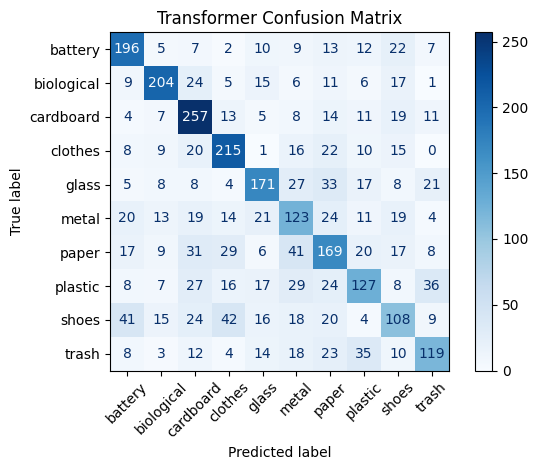

Transformer confusion matrix generated successfully!


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_transformer = confusion_matrix(
    y_test_cnn,
    transformer_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_transformer,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Transformer Confusion Matrix")
plt.tight_layout()
plt.show()

print("Transformer confusion matrix generated successfully!")

### 1️⃣2️⃣TRANSFORMER ACCURACY GRAPH

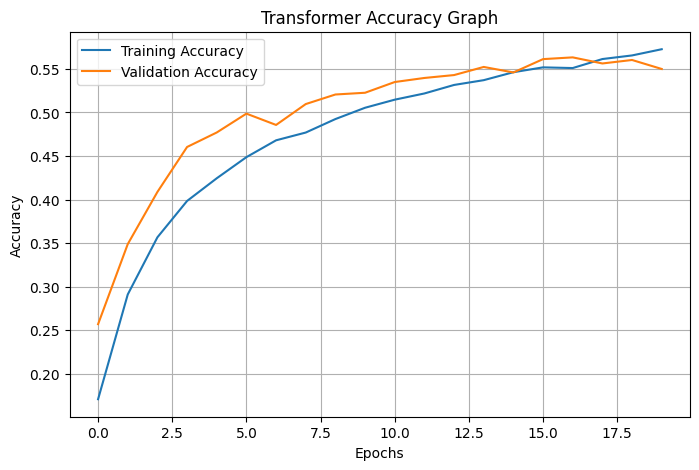

Transformer accuracy graph generated successfully!


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    transformer_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    transformer_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Transformer Accuracy Graph")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

print("Transformer accuracy graph generated successfully!")

### 1️⃣3️⃣TRANSFORMER LOSS GRAPH

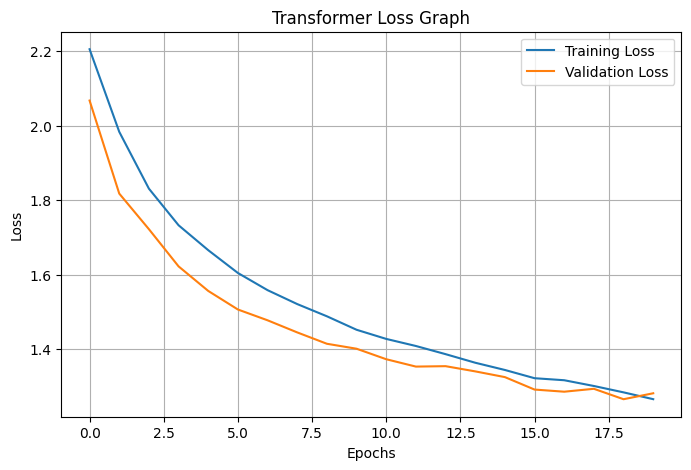

Transformer loss graph generated successfully!


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    transformer_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    transformer_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Transformer Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

print("Transformer loss graph generated successfully!")

## 4️⃣6️⃣FINAL COMPARISION OF ALL MODELS

### 1️⃣COMPARISION TABLE

In [ ]:
final_comparison = pd.DataFrame({

    "Model": [
        "Random Forest",
        "SVM",
        "ANN",
        "CNN",
        "Grid Search CNN",
        "Transformer"
    ],

    "Accuracy (%)": [
        rf_accuracy * 100,
        svm_accuracy * 100,
        test_accuracy * 100,
        cnn_test_accuracy * 100,
        best_cnn_accuracy * 100,
        transformer_test_accuracy * 100
    ]
})

final_comparison = final_comparison.sort_values(
    by="Accuracy (%)",
    ascending=False
)

print(final_comparison)

print("Final model comparison completed successfully!")

             Model  Accuracy (%)
1              SVM     97.371048
2              ANN     96.106488
0    Random Forest     94.975042
3              CNN     78.702164
4  Grid Search CNN     64.359403
5      Transformer     56.206322
Final model comparison completed successfully!


### 2️⃣FINAL COMPARISION GRAPH

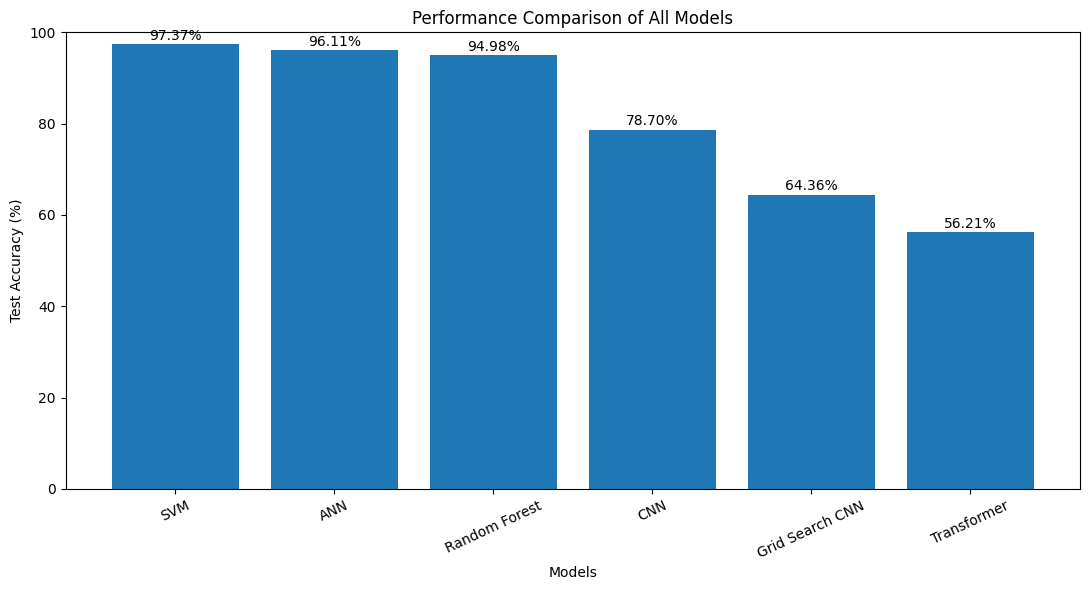

Final comparison graph generated successfully!


In [ ]:
plt.figure(figsize=(11, 6))

plt.bar(
    final_comparison["Model"],
    final_comparison["Accuracy (%)"]
)

plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.title("Performance Comparison of All Models")

plt.ylim(0, 100)
plt.xticks(rotation=25)

for i, value in enumerate(final_comparison["Accuracy (%)"]):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("Final comparison graph generated successfully!")

### 3️⃣SAVED TRAINED MODELS

In [ ]:
ann_model.save("/content/ann_model.keras")

cnn_model.save("/content/cnn_model.keras")

best_cnn_model.save("/content/best_cnn_model.keras")

transformer_model.save("/content/transformer_model.keras")

print("All deep learning models saved successfully!")

All deep learning models saved successfully!
